# LangSmith in Production — TicketPilot

**Solace Systems** runs **TicketPilot**, a LangGraph agent that triages incoming support
tickets, optionally looks up a knowledge-base article, and drafts a reply. It's already
live. This notebook picks up from there and covers the three things a team actually does
once an LLM app is in production:

1. **Curate eval datasets from production traces** — turn real traffic into a versioned,
   trustworthy golden dataset.
2. **Latency dashboards (P50/P95/P99) and annotation queues** — measure how the system
   behaves in the wild, and route the interesting cases to a human reviewer.
3. **Prompt flow versioning and A/B comparison** — move a prompt into version control,
   compare two candidates, and promote a winner.

## How this notebook runs

Every external call (Groq, Tavily, LangSmith) has a real path and an offline "double."
If a key is present in your `.env`, the real service is used. If not, a deterministic
offline stand-in kicks in so every cell still runs end-to-end and produces sane output.
Nothing here is hidden — the doubles are ordinary Python you can read top to bottom, and
you'll see exactly which mode you're in from the banner the first cell prints.

Create a `.env` file next to this notebook with:

```
GROQ_API_KEY=
GROQ_MODEL=
LANGSMITH_TRACING=
LANGSMITH_API_KEY=
LANGSMITH_PROJECT=
TAVILY_API_KEY=
```

Leave any value blank to run that piece offline. `GROQ_MODEL` defaults to
`openai/gpt-oss-20b` if left blank, and `LANGSMITH_PROJECT` defaults to
`ticketpilot-production`.

## Source docs for this module

- [Manage datasets](https://docs.langchain.com/langsmith/manage-datasets)
- [Monitor projects with dashboards](https://docs.langchain.com/langsmith/dashboards)
- [Use annotation queues](https://docs.langchain.com/langsmith/annotation-queues)
- [Prompt engineering concepts](https://docs.langchain.com/langsmith/prompt-engineering-concepts)

In [1]:
import os
import hashlib
import json
import statistics
import time
import uuid
from datetime import datetime, timedelta, timezone

import numpy as np
from dotenv import load_dotenv

load_dotenv()


def stable_hash(text: str) -> int:
    # Python's built-in hash() on strings is randomized per process (PYTHONHASHSEED),
    # so it can't be used for reproducible "deterministic jitter" across runs. This
    # uses a real hash digest instead, which is stable no matter when you run it.
    return int(hashlib.md5(text.encode("utf-8")).hexdigest(), 16)

GROQ_API_KEY = os.environ.get("GROQ_API_KEY", "").strip()
GROQ_MODEL = os.environ.get("GROQ_MODEL", "").strip() or "openai/gpt-oss-20b"
LANGSMITH_API_KEY = os.environ.get("LANGSMITH_API_KEY", "").strip()
LANGSMITH_PROJECT = os.environ.get("LANGSMITH_PROJECT", "").strip() or "ticketpilot-production"
TAVILY_API_KEY = os.environ.get("TAVILY_API_KEY", "").strip()

GROQ_LIVE = bool(GROQ_API_KEY)
LANGSMITH_LIVE = bool(LANGSMITH_API_KEY)
TAVILY_LIVE = bool(TAVILY_API_KEY)

# Propagate to the environment so LangChain's built-in tracing picks it up
# automatically whenever LangSmith is live.
os.environ["LANGSMITH_PROJECT"] = LANGSMITH_PROJECT
os.environ["LANGSMITH_TRACING"] = "true" if LANGSMITH_LIVE else "false"
if LANGSMITH_API_KEY:
    os.environ["LANGSMITH_API_KEY"] = LANGSMITH_API_KEY

print("=" * 64)
print("TicketPilot -- LangSmith in Production")
print("=" * 64)
print(f"{'Groq LLM':<16}: {'LIVE (' + GROQ_MODEL + ')' if GROQ_LIVE else 'OFFLINE (FakeChatModel double)'}")
print(f"{'Tavily search':<16}: {'LIVE' if TAVILY_LIVE else 'OFFLINE (canned KB double)'}")
print(f"{'LangSmith':<16}: {'LIVE (project: ' + LANGSMITH_PROJECT + ')' if LANGSMITH_LIVE else 'OFFLINE (MockLangSmithClient double)'}")
print("=" * 64)
if not (GROQ_LIVE and LANGSMITH_LIVE and TAVILY_LIVE):
    print("Running with one or more offline doubles -- every cell below still executes end-to-end.")
    print("Drop real keys into your .env and re-run to switch any piece to live.")

TicketPilot -- LangSmith in Production
Groq LLM        : LIVE (llama-3.3-70b-versatile)
Tavily search   : LIVE
LangSmith       : LIVE (project: ticketpilot-production)


## Offline doubles

Three components can be live or offline: the chat model, the KB search tool, and the
LangSmith client itself. Each offline double mirrors the **exact method signatures** of
the real thing, so nothing downstream needs to know which mode it's in — only this cell
and the next one change.

- `FakeChatModel` — a real `BaseChatModel` subclass. It reads a `TASK:` marker out of the
  system prompt (`triage`, `respond`, or `judge`) and returns deterministic, plausible
  output for that task instead of calling Groq.
- `fake_kb_search` — returns a canned knowledge-base snippet instead of calling Tavily.
- `MockLangSmithClient` (further down) — an in-memory stand-in for `langsmith.Client`
  that implements `list_runs`, `create_dataset`, `create_examples`,
  `update_dataset_tag`, `list_examples`, `create_feedback_config`,
  `create_annotation_queue`, `add_runs_to_annotation_queue`, `create_feedback`,
  `push_prompt`, and `pull_prompt` — the same calls you'd make against the real API.

In [2]:
from langchain_core.language_models.chat_models import BaseChatModel
from langchain_core.messages import AIMessage
from langchain_core.outputs import ChatGeneration, ChatResult

CATEGORY_KEYWORDS = {
    "billing": ["refund", "invoice", "charge", "payment", "subscription", "billed"],
    "technical": ["error", "crash", "bug", "not working", "broken", "500", "freeze", "freezes"],
    "account": ["password", "login", "locked", "access", "2fa", "sign in"],
    "feature_request": ["feature", "request", "would be great", "suggestion", "add support", "consider adding"],
}
NEEDS_SEARCH_CATEGORIES = {"technical", "account"}


def detect_category(text: str) -> str:
    lowered = text.lower()
    scores = {cat: sum(1 for kw in kws if kw in lowered) for cat, kws in CATEGORY_KEYWORDS.items()}
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else "billing"


KB_SNIPPETS = {
    "technical": "KB#118 -- Ask the customer to force-quit the app, clear the local cache, and relaunch. "
                 "If the error persists, escalate with the error code and a screenshot.",
    "account": "KB#204 -- Guide the customer to Settings > Security > Reset Password. If they are locked out "
               "after repeated 2FA failures, confirm identity via the recovery email before unlocking.",
}


def fake_kb_search(query: str):
    '''Offline double for the Tavily KB-search tool.'''
    category = detect_category(query)
    snippet = KB_SNIPPETS.get(category, "KB#000 -- No specific article found; use general troubleshooting steps.")
    return [{"title": f"{category.replace('_', ' ').title()} help article", "content": snippet}]


def _offline_judge_score(prompt_text: str) -> str:
    '''Deterministic stand-in for an LLM-as-judge score. Combines how much
    ticket-relevant content the candidate reply covers (ignoring common stopwords, so
    style differences don't get penalized as if they were missing content) with whether
    its length falls in a sensible support-reply range -- two legible, inspectable
    proxies for quality instead of a black box. Capped below 1.0 on purpose: even a
    strong match should not look like a perfect score.'''
    if "CANDIDATE:" not in prompt_text or "REFERENCE:" not in prompt_text:
        return "0.75"
    candidate = prompt_text.split("CANDIDATE:")[1].split("REFERENCE:")[0]
    reference = prompt_text.split("REFERENCE:")[1]

    stopwords = {
        "the", "a", "an", "and", "or", "to", "of", "in", "on", "for", "is", "are", "i",
        "you", "your", "this", "that", "it", "we", "us", "our", "with", "as", "be",
        "have", "has", "will", "know", "stay", "until", "please", "thanks", "hi",
        "there", "reaching", "out",
    }

    def content_words(text):
        return {w.strip(".,!?'\"-") for w in text.lower().split()} - stopwords

    cand_words = content_words(candidate)
    ref_words = content_words(reference)
    coverage = len(cand_words & ref_words) / max(len(ref_words), 1)

    word_count = len(candidate.split())
    ideal_length = 38
    length_score = 1.0 - min(abs(word_count - ideal_length) / 20, 1.0)

    jitter = (stable_hash(candidate) % 11 - 5) / 100  # deterministic -0.05 .. +0.05
    raw = 0.30 * coverage + 0.45 * length_score + 0.20 + jitter
    return f"{max(0.55, min(0.95, raw)):.2f}"


def _offline_reply(prompt_text: str, style: str) -> str:
    category = detect_category(prompt_text)
    kb_note = ""
    if "KB#" in prompt_text:
        kb_note = " Based on our internal notes, this looks like a known issue we already have a fix for."
    label = category.replace("_", " ")
    if style == "empathetic":
        return (
            f"Hi, I'm sorry for the trouble with your {label} issue -- I know that's frustrating.{kb_note} "
            f"I'll stay on this until it's fully resolved. Here are the next steps."
        )
    return f"Thanks for reaching out. This looks like a {label} issue.{kb_note} Here are the next steps."


class FakeChatModel(BaseChatModel):
    '''Deterministic offline double for ChatGroq. Dispatches on a TASK marker embedded
    in the system prompt so the same object can stand in for the triage step, the
    respond step, and the judge step.'''

    @property
    def _llm_type(self) -> str:
        return "fake-ticketpilot-model"

    def _generate(self, messages, stop=None, run_manager=None, **kwargs):
        system_text = messages[0].content if messages else ""
        human_text = messages[-1].content if messages else ""

        if "TASK: triage" in system_text:
            category = detect_category(human_text)
            needs_search = category in NEEDS_SEARCH_CATEGORIES
            content = json.dumps({"category": category, "needs_kb_search": needs_search})
        elif "TASK: judge" in system_text:
            content = _offline_judge_score(human_text)
        elif "TASK: respond" in system_text:
            style = "empathetic" if "STYLE: empathetic" in system_text else "concise"
            content = _offline_reply(human_text, style)
        else:
            content = "OK"

        return ChatResult(generations=[ChatGeneration(message=AIMessage(content=content))])

C:\Users\MadhiarasanM\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
if GROQ_LIVE:
    from langchain_groq import ChatGroq
    llm = ChatGroq(model=GROQ_MODEL, groq_api_key=GROQ_API_KEY, temperature=0.2)
else:
    llm = FakeChatModel()

if TAVILY_LIVE:
    from langchain_tavily import TavilySearch
    _tavily = TavilySearch(max_results=3, tavily_api_key=TAVILY_API_KEY)

    def kb_search_tool(query: str):
        result = _tavily.invoke({"query": query})
        return result.get("results", []) if isinstance(result, dict) else result
else:
    kb_search_tool = fake_kb_search

print(f"llm            -> {type(llm).__name__}")
print(f"kb_search_tool -> {'TavilySearch (live)' if TAVILY_LIVE else 'fake_kb_search (offline)'}")

llm            -> ChatGroq
kb_search_tool -> TavilySearch (live)


In [4]:
from langsmith import Client


class MockLangSmithClient:
    '''In-memory double for langsmith.Client. Every public method here has the same
    name and the same keyword arguments as the real SDK method it stands in for --
    the rest of this notebook calls `ls_client.<method>(...)` the same way whether
    `ls_client` is this class or the real thing.'''

    class _Run:
        def __init__(self, id, name, inputs, outputs, start_time, end_time, tags, extra):
            self.id = id
            self.name = name
            self.inputs = inputs
            self.outputs = outputs
            self.start_time = start_time
            self.end_time = end_time
            self.tags = tags
            self.extra = extra  # extra["metadata"] mirrors the real Run schema

    class _Dataset:
        def __init__(self, id, name, description):
            self.id = id
            self.name = name
            self.description = description

    class _Example:
        def __init__(self, id, inputs, outputs, metadata):
            self.id = id
            self.inputs = inputs
            self.outputs = outputs
            self.metadata = metadata or {}

    class _Queue:
        def __init__(self, id, name, description, rubric_instructions, rubric_items):
            self.id = id
            self.name = name
            self.description = description
            self.rubric_instructions = rubric_instructions
            self.rubric_items = rubric_items or []

    def __init__(self):
        self._runs = {}
        self._datasets = {}          # name -> _Dataset
        self._examples = {}          # dataset_name -> list[_Example]
        self._dataset_tags = {}      # dataset_name -> {tag: [example ids as of that tag]}
        self._feedback_configs = {}  # key -> config dict
        self._queues = {}            # id -> _Queue
        self._queue_runs = {}        # queue_id -> [run_id, ...]
        self._feedback = []          # list of feedback dicts
        self._prompts = {}           # name -> {"commits": {hash: object}, "tags": {tag: hash}, "order": [hash,...]}

    # -- runs -----------------------------------------------------------
    def record_run(self, run_id, name, inputs, outputs, start_time, end_time, tags, metadata):
        '''Offline-only ingestion helper. The real Client ingests runs automatically
        via tracing; here we record them by hand so `list_runs` has something to return.'''
        self._runs[run_id] = self._Run(
            id=run_id, name=name, inputs=inputs, outputs=outputs,
            start_time=start_time, end_time=end_time, tags=tags,
            extra={"metadata": metadata},
        )

    def list_runs(self, project_name=None, is_root=None, **kwargs):
        return list(self._runs.values())

    # -- datasets ---------------------------------------------------------
    def create_dataset(self, dataset_name, description=None):
        ds = self._Dataset(id=str(uuid.uuid4()), name=dataset_name, description=description)
        self._datasets[dataset_name] = ds
        self._examples.setdefault(dataset_name, [])
        return ds

    def create_examples(self, dataset_id=None, dataset_name=None, inputs=None, outputs=None, metadata=None):
        if dataset_name is None:
            dataset_name = next(d.name for d in self._datasets.values() if d.id == dataset_id)
        inputs = inputs or []
        outputs = outputs or [None] * len(inputs)
        metadata = metadata or [None] * len(inputs)
        for i, o, m in zip(inputs, outputs, metadata):
            self._examples[dataset_name].append(self._Example(id=str(uuid.uuid4()), inputs=i, outputs=o, metadata=m))

    def update_dataset_tag(self, dataset_name, as_of=None, tag=None):
        snapshot_ids = [ex.id for ex in self._examples.get(dataset_name, [])]
        self._dataset_tags.setdefault(dataset_name, {})[tag] = snapshot_ids

    def list_examples(self, dataset_name, as_of=None):
        all_examples = self._examples.get(dataset_name, [])
        if as_of is None or as_of == "latest":
            return list(all_examples)
        tag_ids = self._dataset_tags.get(dataset_name, {}).get(as_of)
        if tag_ids is None:
            return list(all_examples)
        by_id = {ex.id: ex for ex in all_examples}
        return [by_id[i] for i in tag_ids if i in by_id]

    # -- feedback & annotation queues --------------------------------------
    def create_feedback_config(self, key, feedback_config, is_lower_score_better=None):
        self._feedback_configs[key] = {
            "feedback_config": feedback_config,
            "is_lower_score_better": is_lower_score_better,
        }

    def create_annotation_queue(self, name, description=None, rubric_instructions=None, rubric_items=None):
        q = self._Queue(
            id=str(uuid.uuid4()), name=name, description=description,
            rubric_instructions=rubric_instructions, rubric_items=rubric_items,
        )
        self._queues[q.id] = q
        self._queue_runs[q.id] = []
        return q

    def add_runs_to_annotation_queue(self, queue_id, run_ids=None):
        self._queue_runs.setdefault(queue_id, []).extend(run_ids or [])

    def create_feedback(self, run_id, key, score=None, value=None, comment=None):
        self._feedback.append({
            "run_id": run_id, "key": key, "score": score, "value": value,
            "comment": comment, "created_at": datetime.now(timezone.utc),
        })

    # -- prompts ------------------------------------------------------------
    def push_prompt(self, prompt_identifier, object=None, commit_tags=None, description=None, parent_commit_hash="latest"):
        repo = self._prompts.setdefault(prompt_identifier, {"commits": {}, "tags": {}, "order": []})
        commit_hash = uuid.uuid4().hex[:8]
        repo["commits"][commit_hash] = object
        repo["order"].append(commit_hash)
        for tag in (commit_tags or []):
            repo["tags"][tag] = commit_hash
        return f"https://smith.langchain.com/prompts/{prompt_identifier}/{commit_hash}"

    def pull_prompt(self, identifier):
        name, _, ref = identifier.partition(":")
        repo = self._prompts[name]
        if not ref or ref == "latest":
            commit_hash = repo["order"][-1]
        elif ref in repo["tags"]:
            commit_hash = repo["tags"][ref]
        else:
            commit_hash = ref  # assume it's already a commit hash
        stored = repo["commits"][commit_hash]
        prompt_copy = stored.model_copy(deep=True)
        tags_here = [t for t, h in repo["tags"].items() if h == commit_hash]
        prompt_copy.metadata = {"lc_hub_commit_hash": commit_hash, "tags": tags_here}
        return prompt_copy


ls_client = Client() if LANGSMITH_LIVE else MockLangSmithClient()
print(f"ls_client -> {type(ls_client).__name__}")

ls_client -> Client


## 1. Build TicketPilot, then generate real production traffic

The agent is a small LangGraph graph: **triage** the ticket, optionally **search the
knowledge base**, then **respond**. Because `LANGSMITH_TRACING` is set from the first
cell, every `.invoke()` call below is automatically logged as a trace in your LangSmith
project when running live -- that's the "production traces" the rest of this notebook
works from.

In [5]:
from typing import Optional, TypedDict

from langchain_core.prompts import ChatPromptTemplate
from langgraph.graph import END, START, StateGraph

TRIAGE_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You are TicketPilot's triage assistant. TASK: triage. "
     "Classify the ticket into exactly one of: billing, technical, account, feature_request. "
     "Decide whether a knowledge-base search would help resolve it. "
     "Respond with ONLY compact JSON, e.g. {{\"category\": \"technical\", \"needs_kb_search\": true}}."),
    ("human", "{ticket_text}"),
])

# The prompt actually driving production replies today -- still a hardcoded string.
# Section 4 walks through moving this exact wording into LangSmith's Prompt Hub.
BASELINE_RESPOND_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You are TicketPilot's reply-drafting assistant. TASK: respond. STYLE: concise. "
     "Write a short, direct reply to the customer. Use any knowledge-base notes provided."),
    ("human", "Ticket: {ticket_text}\n\nKnowledge base notes: {kb_notes}"),
])


class AgentState(TypedDict):
    ticket_id: str
    ticket_text: str
    category: Optional[str]
    needs_kb_search: Optional[bool]
    kb_results: Optional[list]
    response: Optional[str]


def triage_node(state: AgentState) -> dict:
    messages = TRIAGE_PROMPT.format_messages(ticket_text=state["ticket_text"])
    raw = llm.invoke(messages).content
    try:
        parsed = json.loads(raw)
        category = parsed.get("category", "billing")
        needs_kb_search = bool(parsed.get("needs_kb_search", False))
    except (json.JSONDecodeError, AttributeError):
        category, needs_kb_search = "billing", False
    return {"category": category, "needs_kb_search": needs_kb_search}


def kb_search_node(state: AgentState) -> dict:
    return {"kb_results": kb_search_tool(state["ticket_text"])}


def route_after_triage(state: AgentState) -> str:
    return "kb_search" if state["needs_kb_search"] else "respond"


def make_respond_node(prompt_template):
    def respond_node(state: AgentState) -> dict:
        kb_notes = "\n".join(r.get("content", "") for r in (state.get("kb_results") or [])) or "None"
        messages = prompt_template.format_messages(ticket_text=state["ticket_text"], kb_notes=kb_notes)
        return {"response": llm.invoke(messages).content}
    return respond_node


def build_ticketpilot_graph(respond_prompt_template=BASELINE_RESPOND_PROMPT):
    graph = StateGraph(AgentState)
    graph.add_node("triage", triage_node)
    graph.add_node("kb_search", kb_search_node)
    graph.add_node("respond", make_respond_node(respond_prompt_template))
    graph.add_edge(START, "triage")
    graph.add_conditional_edges("triage", route_after_triage, {"kb_search": "kb_search", "respond": "respond"})
    graph.add_edge("kb_search", "respond")
    graph.add_edge("respond", END)
    return graph.compile()


ticketpilot_agent = build_ticketpilot_graph()
print("TicketPilot agent compiled: triage -> [kb_search] -> respond")

TicketPilot agent compiled: triage -> [kb_search] -> respond


### 20 live support tickets

A balanced mix across the four categories, with enough variety that triage, KB lookups,
and reply length all differ ticket to ticket -- exactly the kind of variation a real
production log has.

In [6]:
TICKETS = [
    {"id": "T-01", "text": "I was charged twice for my subscription this month, can I get a refund for the duplicate charge?"},
    {"id": "T-02", "text": "My invoice for March shows an incorrect amount, it's $10 more than my plan price."},
    {"id": "T-03", "text": "I want to cancel my subscription but I'm still being billed after cancellation."},
    {"id": "T-04", "text": "Can you explain the extra charge on my last invoice? I don't recognize it."},
    {"id": "T-05", "text": "I upgraded my plan but the payment failed, yet I was still charged."},
    {"id": "T-06", "text": "The dashboard keeps crashing every time I try to export a report."},
    {"id": "T-07", "text": "I'm getting a 500 error whenever I upload a CSV file larger than 10MB."},
    {"id": "T-08", "text": "The mobile app is not working after the latest update, it freezes on launch."},
    {"id": "T-09", "text": "Search results are broken, queries return no results even for valid terms."},
    {"id": "T-10", "text": "The API is returning errors intermittently for the /tickets endpoint."},
    {"id": "T-11", "text": "I can't log in, it says my password is incorrect even after resetting it."},
    {"id": "T-12", "text": "My account got locked after too many failed 2FA attempts."},
    {"id": "T-13", "text": "I never received the password reset email, can you help me regain access?"},
    {"id": "T-14", "text": "Someone else seems to have access to my account, I did not authorize this."},
    {"id": "T-15", "text": "I'm locked out of my account because my email address changed."},
    {"id": "T-16", "text": "It would be great if you added dark mode support to the dashboard."},
    {"id": "T-17", "text": "Can you add support for exporting reports directly to Google Sheets?"},
    {"id": "T-18", "text": "We'd love a feature to bulk-assign tickets to team members."},
    {"id": "T-19", "text": "Please consider adding keyboard shortcuts for common actions."},
    {"id": "T-20", "text": "A request: allow us to customize the notification email templates."},
]
print(f"{len(TICKETS)} tickets queued")

20 tickets queued


### Run the tickets, log every call as a production trace

In live mode we use LangChain's `collect_runs()` context manager to capture the real
`run_id` LangSmith assigns to each invocation. In offline mode there's no server to
assign one, so we generate a local id and hand the run to `ls_client.record_run(...)`
ourselves -- the mock's version of what LangSmith's ingestion pipeline does for you
automatically when live.

One more offline-only detail: without a real network call, every invocation finishes in
a few milliseconds, which would make a latency dashboard pointless. So *only* in offline
mode we layer in a small, deterministic simulated processing delay per category (KB
lookups take longer than a quick billing reply) so the P50/P95/P99 lesson later has
something real to show. In live mode, every millisecond you see is genuinely measured.

In [7]:
from langchain_core.tracers.context import collect_runs

# Offline-only simulated latency, seconds. Categories that trigger a KB search are
# slower, mirroring a real system where the extra tool call costs real time. One ticket
# is pinned as a deliberate slow outlier -- a large-file edge case that took a lot
# longer -- so P95/P99 actually diverge from P50 instead of collapsing together, the
# way a real "long tail" does.
_SIMULATED_OFFLINE_LATENCY = {
    "billing": 0.15,
    "technical": 0.45,
    "account": 0.40,
    "feature_request": 0.10,
}
_SIMULATED_OFFLINE_OUTLIERS = {"T-07": 1.35}  # the 10MB-CSV-upload ticket


def _simulated_offline_latency(category: str, ticket_id: str) -> float:
    if ticket_id in _SIMULATED_OFFLINE_OUTLIERS:
        return _SIMULATED_OFFLINE_OUTLIERS[ticket_id]
    base = _SIMULATED_OFFLINE_LATENCY.get(category, 0.2)
    jitter = (stable_hash(ticket_id) % 100) / 1000  # deterministic 0.000-0.099s jitter
    return round(base + jitter, 3)


def invoke_ticket(ticket: dict) -> dict:
    config = {
        "run_name": f"ticket-{ticket['id']}",
        "tags": ["production", "ticketpilot"],
        "metadata": {"ticket_id": ticket["id"]},
    }
    start_ts = datetime.now(timezone.utc)

    if LANGSMITH_LIVE:
        wall_start = time.perf_counter()
        with collect_runs() as cb:
            result = ticketpilot_agent.invoke(
                {"ticket_id": ticket["id"], "ticket_text": ticket["text"]}, config=config
            )
        latency_s = round(time.perf_counter() - wall_start, 3)
        run_id = str(cb.traced_runs[0].id) if cb.traced_runs else str(uuid.uuid4())
    else:
        result = ticketpilot_agent.invoke(
            {"ticket_id": ticket["id"], "ticket_text": ticket["text"]}, config=config
        )
        latency_s = _simulated_offline_latency(result["category"], ticket["id"])
        run_id = str(uuid.uuid4())

    end_ts = start_ts + timedelta(seconds=latency_s)

    if not LANGSMITH_LIVE:
        ls_client.record_run(
            run_id=run_id,
            name=config["run_name"],
            inputs={"ticket_text": ticket["text"]},
            outputs={
                "category": result["category"],
                "kb_results": result.get("kb_results") or [],
                "response": result["response"],
            },
            start_time=start_ts,
            end_time=end_ts,
            tags=config["tags"],
            metadata={"ticket_id": ticket["id"], "needs_kb_search": result["needs_kb_search"]},
        )

    return {
        "run_id": run_id,
        "ticket_id": ticket["id"],
        "category": result["category"],
        "needs_kb_search": result["needs_kb_search"],
        "response": result["response"],
        "latency_s": latency_s,
    }


production_results = [invoke_ticket(t) for t in TICKETS]
print(f"Ran {len(production_results)} tickets through TicketPilot")
if LANGSMITH_LIVE:
    print("Traces are landing in LangSmith asynchronously -- giving ingestion a moment before we query them back.")
    time.sleep(2)

Ran 20 tickets through TicketPilot
Traces are landing in LangSmith asynchronously -- giving ingestion a moment before we query them back.


In [8]:
avg_latency = statistics.mean(r["latency_s"] for r in production_results)
kb_rate = sum(r["needs_kb_search"] for r in production_results) / len(production_results)
by_category = {}
for r in production_results:
    by_category[r["category"]] = by_category.get(r["category"], 0) + 1

print(f"Average latency   : {avg_latency:.3f}s")
print(f"KB search rate    : {kb_rate:.0%}")
print(f"Category breakdown: {by_category}")

Average latency   : 1.978s
KB search rate    : 25%
Category breakdown: {'billing': 5, 'technical': 7, 'account': 3, 'feature_request': 5}


## 2. Curate eval datasets from production traces

A golden dataset should reflect what actually happens in production, not what you
imagine happens. LangSmith [datasets are versioned](https://docs.langchain.com/langsmith/manage-datasets#version-a-dataset):
every add/update/delete creates a new version, and you can tag a version (e.g. `prod`)
so you can always point evaluation at a stable, named snapshot instead of a moving
target.

The workflow: query production runs back out of LangSmith, decide which ones are worth
keeping as eval examples, then build and tag a dataset from them.

In [9]:
def get_metadata(run):
    return (run.extra or {}).get("metadata", {})


production_runs = list(ls_client.list_runs(project_name=LANGSMITH_PROJECT, is_root=True))
print(f"Fetched {len(production_runs)} production runs from project '{LANGSMITH_PROJECT}'")

latencies = [(r.end_time - r.start_time).total_seconds() for r in production_runs]
p75_latency = np.percentile(latencies, 75)

# Curation criteria: keep runs that needed a KB search (the harder, more interesting
# cases) or that landed in the slowest quartile (worth a closer look either way).
curated_runs = [
    r for r in production_runs
    if get_metadata(r).get("needs_kb_search") or (r.end_time - r.start_time).total_seconds() >= p75_latency
]
print(f"Curated {len(curated_runs)} of {len(production_runs)} runs as eval candidates "
      f"(KB-search used, or latency >= P75 = {p75_latency:.3f}s)")

Fetched 60 production runs from project 'ticketpilot-production'
Curated 15 of 60 runs as eval candidates (KB-search used, or latency >= P75 = 1.492s)


In [12]:
def kb_notes_from(run) -> str:
    return "\n".join(item.get("content", "") for item in (run.outputs.get("kb_results") or [])) or "None"


DATASET_NAME = "ticketpilot-support-eval"

try:
    dataset = ls_client.create_dataset(
        dataset_name=DATASET_NAME,
        description="Golden examples curated from TicketPilot production traces.",
    )
    print(f"Dataset '{dataset.name}' created")
except Exception as e:
    # LangSmith raises a 409 if a dataset with this name already exists -- which
    # happens any time this cell is re-run. Not a real failure: just reuse it.
    if "already exists" in str(e) or "409" in str(e):
        dataset = ls_client.read_dataset(dataset_name=DATASET_NAME)
        print(f"Dataset '{dataset.name}' already exists -- reusing it")
    else:
        raise

ls_client.create_examples(
    dataset_id=dataset.id,
    inputs=[
        {"ticket_text": r.inputs["ticket_text"], "category": r.outputs["category"], "kb_notes": kb_notes_from(r)}
        for r in curated_runs
    ],
    outputs=[{"reference_response": r.outputs["response"]} for r in curated_runs],
    metadata=[
        {"source_run_id": r.id, "ticket_id": get_metadata(r).get("ticket_id")} for r in curated_runs
    ],
)
print(f"Added {len(curated_runs)} examples to '{dataset.name}'")

Dataset 'ticketpilot-support-eval' already exists -- reusing it
Added 15 examples to 'ticketpilot-support-eval'


In [13]:
ls_client.update_dataset_tag(dataset_name="ticketpilot-support-eval", as_of=datetime.now(timezone.utc), tag="golden-v1")
tagged = list(ls_client.list_examples(dataset_name="ticketpilot-support-eval", as_of="golden-v1"))
print(f"Tag 'golden-v1' points to a snapshot of {len(tagged)} examples")
for ex in tagged[:3]:
    print(f"  - [{ex.inputs['category']}] {ex.inputs['ticket_text'][:60]}...")

Tag 'golden-v1' points to a snapshot of 24 examples
  - [technical] The mobile app is not working after the latest update, it fr...
  - [feature_request] Can you add support for exporting reports directly to Google...
  - [feature_request] It would be great if you added dark mode support to the dash...


In the UI, the equivalent of this last step is [exporting filtered traces from an
experiment back into a dataset](https://docs.langchain.com/langsmith/manage-datasets#export-filtered-traces-from-experiment-to-dataset):
filter a tracing project down to the runs you care about, multi-select, and click **Add
to Dataset**. What we just did programmatically is the same operation, useful when the
curation logic is more than a filter click can express.

## 3. Latency dashboards: P50 / P95 / P99

LangSmith's [prebuilt dashboards](https://docs.langchain.com/langsmith/dashboards#prebuilt-dashboards)
give every project trace count, latency, and error-rate charts automatically. Custom
dashboards let you pick a metric (like latency), a chart type, and a `group by` to build
exactly the view you need.

Percentiles matter more than an average here: P50 is the typical ticket, but P95/P99
are the ones a customer actually complains about. We'll pull the same latency numbers a
dashboard chart would use and compute them directly.

In [14]:
runs = list(ls_client.list_runs(project_name=LANGSMITH_PROJECT, is_root=True))
latencies_ms = sorted((r.end_time - r.start_time).total_seconds() * 1000 for r in runs)

p50, p95, p99 = np.percentile(latencies_ms, [50, 95, 99])
print(f"P50: {p50:.0f} ms")
print(f"P95: {p95:.0f} ms")
print(f"P99: {p99:.0f} ms")
print(f"Max: {max(latencies_ms):.0f} ms")

P50: 700 ms
P95: 4809 ms
P99: 5418 ms
Max: 5960 ms


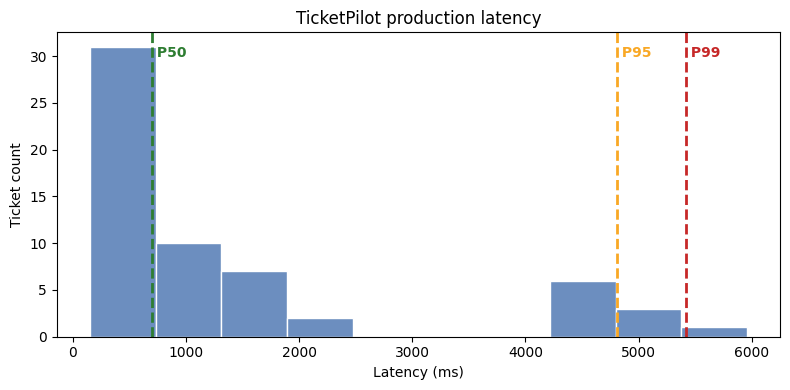

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(latencies_ms, bins=10, color="#6C8EBF", edgecolor="white")
for value, label, color in [(p50, "P50", "#2E7D32"), (p95, "P95", "#F9A825"), (p99, "P99", "#C62828")]:
    ax.axvline(value, color=color, linestyle="--", linewidth=2)
    ax.text(value, ax.get_ylim()[1] * 0.92, f" {label}", color=color, fontsize=10, fontweight="bold")
ax.set_xlabel("Latency (ms)")
ax.set_ylabel("Ticket count")
ax.set_title("TicketPilot production latency")
plt.tight_layout()
plt.show()

Building the same chart in the LangSmith UI: **Monitor -> New Dashboard -> New Chart**,
pick the tracing project, set the metric to latency, and LangSmith gives you P50/P95/P99
series out of the box -- no manual percentile math needed there. `group by` (run tag or
metadata) is how you'd split this into one line per ticket category to see whether
`technical` tickets are dragging up your P99.

### Annotation queues

[Annotation queues](https://docs.langchain.com/langsmith/annotation-queues) give a
reviewer a focused, one-run-at-a-time (or pairwise) view for attaching feedback, instead
of clicking into traces one by one. Building one programmatically has three layers:

1. **Feedback configs** — the schema for a score (continuous, categorical, or freeform).
2. **A queue with rubric items** — which feedback configs a reviewer fills out for this
   queue.
3. **Runs added to the queue** — the actual work items.

We'll route the runs most worth a second look — the slowest (P95+) and the
account-security ones (always sensitive) — into a review queue.

In [17]:
import numpy as np

# 1. Safely handle feedback configs (bypasses if they already exist)
for key, config, lower_better in [
    ("response_quality", {"type": "continuous", "min": 0, "max": 1}, False),
    (
        "needs_escalation",
        {
            "type": "categorical",
            "categories": [
                {"value": 1, "label": "Escalate"},
                {"value": 0, "label": "No escalation needed"},
            ],
        },
        False,
    ),
]:
    try:
        ls_client.create_feedback_config(
            key, feedback_config=config, is_lower_score_better=lower_better
        )
    except Exception:
        pass  # Already exists, move on Safely

# 2. Get or Create the Annotation Queue safely
queue_name = "TicketPilot QA Review"
try:
    review_queue = ls_client.create_annotation_queue(
        name=queue_name,
        description="High-latency and account-security runs held out for human review.",
        rubric_instructions="Rate the reply's quality and flag anything that needs escalation to a senior agent.",
        rubric_items=[
            {
                "feedback_key": "response_quality",
                "description": "How helpful and accurate is the reply?",
                "is_required": True,
            },
            {
                "feedback_key": "needs_escalation",
                "description": "Does this ticket need a senior agent?",
                "is_required": True,
            },
        ],
    )
except Exception as e:
    if "already exists" in str(e).lower():
        # Fallback: Find the existing queue from the workspace list
        review_queue = next(
            q for q in ls_client.list_annotation_queues() if q.name == queue_name
        )
    else:
        raise e

# 3. Calculate latency threshold and filter flagged runs
p95_latency_s = np.percentile(latencies, 95)
flagged_runs = {
    r.id: r
    for r in production_runs
    if (r.end_time - r.start_time).total_seconds() >= p95_latency_s
    or r.outputs.get("category") == "account"
}.values()

# 4. Push to queue if any runs were flagged
if flagged_runs:
    ls_client.add_runs_to_annotation_queue(
        review_queue.id, run_ids=[r.id for r in flagged_runs]
    )
    print(
        f"Queued {len(flagged_runs)} runs in '{review_queue.name}' for review"
    )
else:
    print("No runs met the latency or security criteria for review today.")

Queued 9 runs in 'TicketPilot QA Review' for review


Real annotators do this next part in the LangSmith UI, one run at a time. We simulate
that pass here with a plain heuristic (not an LLM call) so it's obvious exactly why each
run got the score and escalation flag it did — a real reviewer would replace this with
their own judgment.

In [18]:
def simulate_human_review(run):
    original = run.outputs["response"]
    word_count = len(original.split())
    # Heuristic: a reply under 15 words on a non-trivial ticket usually reads as
    # terse rather than efficient -- flag it and give the reviewer a corrected version.
    quality = 0.6 if word_count < 15 else 0.85
    corrected = original
    if quality < 0.85:
        corrected += " I'm escalating this to make sure we fully resolve it for you."
    escalate = 1 if run.outputs.get("category") == "account" or quality < 0.7 else 0
    return quality, corrected, escalate


for run in flagged_runs:
    quality, corrected, escalate = simulate_human_review(run)
    ls_client.create_feedback(run_id=run.id, key="response_quality", score=quality, comment="Simulated reviewer pass")
    ls_client.create_feedback(run_id=run.id, key="needs_escalation", value=escalate)
    run.outputs["reviewed_response"] = corrected
    print(f"  {run.name:<12} quality={quality:.2f}  escalate={'yes' if escalate else 'no '}  category={run.outputs['category']}")

  ticket-T-20  quality=0.85  escalate=no   category=feature_request
  ticket-T-16  quality=0.85  escalate=no   category=feature_request
  ticket-T-15  quality=0.85  escalate=yes  category=account
  ticket-T-14  quality=0.85  escalate=yes  category=account
  ticket-T-12  quality=0.85  escalate=yes  category=account
  ticket-T-16  quality=0.85  escalate=no   category=feature_request
  ticket-T-15  quality=0.85  escalate=yes  category=account
  ticket-T-14  quality=0.85  escalate=yes  category=account
  ticket-T-12  quality=0.85  escalate=yes  category=account


Reviewed runs feed straight back into dataset curation — closing the loop between
Sections 2 and 3. We add the reviewer-corrected responses as a second batch of examples
and tag a new dataset version.

In [19]:
ls_client.create_examples(
    dataset_id=dataset.id,
    inputs=[
        {"ticket_text": r.inputs["ticket_text"], "category": r.outputs["category"], "kb_notes": kb_notes_from(r)}
        for r in flagged_runs
    ],
    outputs=[{"reference_response": r.outputs["reviewed_response"]} for r in flagged_runs],
    metadata=[{"source_run_id": r.id, "reviewed": True} for r in flagged_runs],
)
ls_client.update_dataset_tag(dataset_name="ticketpilot-support-eval", as_of=datetime.now(timezone.utc), tag="golden-v2")
golden_v2 = list(ls_client.list_examples(dataset_name="ticketpilot-support-eval", as_of="golden-v2"))
print(f"Tag 'golden-v2' now points to {len(golden_v2)} examples (original curation + reviewer-corrected)")

Tag 'golden-v2' now points to 24 examples (original curation + reviewer-corrected)


## 4. Prompt flow versioning and A/B comparison

So far `BASELINE_RESPOND_PROMPT` has just been a Python constant. [LangSmith's Prompt
Hub](https://docs.langchain.com/langsmith/prompt-engineering-concepts#prompts-in-langsmith)
turns a prompt into a version-controlled asset: every save is a **commit** with a hash,
and a **tag** (like `prod` or `staging`) is a movable pointer to a specific commit. Code
pulls by tag (`my-prompt:prod`), so promoting a new version is a data change, not a code
change.

We'll push the current baseline as commit 1, tag it `prod`, push a candidate rewrite as
commit 2, then A/B test them against each other before deciding which one actually earns
the `prod` tag.

In [20]:
CANDIDATE_RESPOND_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You are TicketPilot's reply-drafting assistant. TASK: respond. STYLE: empathetic. "
     "Write a warm, empathetic reply that acknowledges the customer's frustration before giving next steps. "
     "Use any knowledge-base notes provided."),
    ("human", "Ticket: {ticket_text}\n\nKnowledge base notes: {kb_notes}"),
])

PROMPT_NAME = "ticketpilot-respond"


def push_prompt_safe(object, commit_tags, description):
    # LangSmith raises a 409 ("Nothing to commit") if the content is byte-for-byte
    # identical to the current tip -- which happens any time this cell is re-run.
    # That's not a real failure, so treat it as "already up to date" and move on.
    try:
        return ls_client.push_prompt(PROMPT_NAME, object=object, commit_tags=commit_tags, description=description)
    except Exception as e:
        if "Nothing to commit" in str(e) or "409" in str(e):
            print(f"  (skipped push -- {commit_tags} content already matches the latest commit)")
            return None
        raise


baseline_url = push_prompt_safe(
    BASELINE_RESPOND_PROMPT, commit_tags=["baseline", "prod"],
    description="Concise baseline reply-drafting prompt (current production wording).",
)
candidate_url = push_prompt_safe(
    CANDIDATE_RESPOND_PROMPT, commit_tags=["candidate"],
    description="Empathetic candidate reply-drafting prompt.",
)
print(f"baseline  commit -> {baseline_url or '(unchanged)'}")
print(f"candidate commit -> {candidate_url or '(unchanged)'}")

prod_prompt = ls_client.pull_prompt(f"{PROMPT_NAME}:prod")
commit_hash = prod_prompt.metadata.get("lc_hub_commit_hash", "unknown")
tags = prod_prompt.metadata.get("tags", "n/a")
print(f"'{PROMPT_NAME}:prod' currently resolves to commit {commit_hash} (tags: {tags})")

  (skipped push -- ['baseline', 'prod'] content already matches the latest commit)
  (skipped push -- ['candidate'] content already matches the latest commit)
baseline  commit -> (unchanged)
candidate commit -> (unchanged)
'ticketpilot-respond:prod' currently resolves to commit 6a58011e528d9553c141038f09c3e716ae26efa76d987114b8eff8cbc6605195 (tags: n/a)


### A/B evaluation + pairwise comparison

For each `golden-v2` example we generate a reply with **both** prompt versions and score
each against the reference with an LLM-as-judge. The judge prompt uses `TASK: judge` so
it routes through the same `llm` object (real or `FakeChatModel`) as everything else —
one model, three jobs.

A true [Pairwise Annotation Queue](https://docs.langchain.com/langsmith/annotation-queues#pairwise-annotation-queues)
is created from the **Datasets & Experiments** UI — it isn't exposed as a first-class
object in the public Python SDK. What it does under the hood, per LangSmith's own docs,
is record **binary feedback on both runs**. That's exactly what we replicate below: pick
a winner per example, log it as feedback on both sides, and tally the result.

In [21]:
JUDGE_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You are a senior support-quality reviewer. TASK: judge. "
     "Score how well the CANDIDATE reply addresses the ticket, compared to the REFERENCE reply. "
     "Respond with ONLY a number between 0 and 1."),
    ("human", "CANDIDATE:\n{candidate}\n\nREFERENCE:\n{reference}"),
])


def judge_response(candidate: str, reference: str) -> float:
    messages = JUDGE_PROMPT.format_messages(candidate=candidate, reference=reference)
    raw = llm.invoke(messages).content.strip()
    try:
        return max(0.0, min(1.0, float(raw)))
    except ValueError:
        return 0.7


def generate_reply(prompt_template, example) -> str:
    messages = prompt_template.format_messages(
        ticket_text=example.inputs["ticket_text"], kb_notes=example.inputs["kb_notes"]
    )
    return llm.invoke(messages).content


ls_client.create_feedback_config(
    "pairwise_preference",
    feedback_config={
        "type": "categorical",
        "categories": [
            {"value": 0, "label": "baseline"},
            {"value": 1, "label": "candidate"},
            {"value": 2, "label": "equal"},
        ],
    },
)

eval_examples = list(ls_client.list_examples(dataset_name="ticketpilot-support-eval", as_of="golden-v2"))
print(f"Evaluating both prompt versions over {len(eval_examples)} golden examples\n")

baseline_scores, candidate_scores = [], []
baseline_wins = candidate_wins = ties = 0

for example in eval_examples:
    baseline_reply = generate_reply(BASELINE_RESPOND_PROMPT, example)
    candidate_reply = generate_reply(CANDIDATE_RESPOND_PROMPT, example)
    reference = example.outputs["reference_response"]

    b_score = judge_response(baseline_reply, reference)
    c_score = judge_response(candidate_reply, reference)
    baseline_scores.append(b_score)
    candidate_scores.append(c_score)

    if abs(b_score - c_score) < 0.03:
        verdict, ties = "equal", ties + 1
    elif c_score > b_score:
        verdict, candidate_wins = "candidate", candidate_wins + 1
    else:
        verdict, baseline_wins = "baseline", baseline_wins + 1

    source_run_id = example.metadata.get("source_run_id", str(example.id))
    ls_client.create_feedback(
        run_id=source_run_id, key="pairwise_preference", value=verdict,
        comment=f"baseline={b_score:.2f} candidate={c_score:.2f}",
    )

print(f"baseline  avg score = {statistics.mean(baseline_scores):.3f}")
print(f"candidate avg score = {statistics.mean(candidate_scores):.3f}")
print(f"\npairwise: candidate wins {candidate_wins}, baseline wins {baseline_wins}, ties {ties} "
      f"(n={len(eval_examples)})")

Evaluating both prompt versions over 24 golden examples

baseline  avg score = 0.960
candidate avg score = 0.796

pairwise: candidate wins 0, baseline wins 21, ties 3 (n=24)


In [22]:
winner_is_candidate = candidate_wins > baseline_wins
winner_prompt = CANDIDATE_RESPOND_PROMPT if winner_is_candidate else BASELINE_RESPOND_PROMPT
winner_label = "candidate" if winner_is_candidate else "baseline"
print(f"Promoting '{winner_label}' to prod ({candidate_wins} candidate wins vs {baseline_wins} baseline wins, {ties} ties)")

try:
    ls_client.push_prompt(
        PROMPT_NAME, object=winner_prompt, commit_tags=["prod"],
        description=f"Promoted '{winner_label}' after A/B + pairwise review.",
    )
except Exception as e:
    # LangSmith refuses to create a new commit when the content is identical to the
    # current tip (409 "Nothing to commit"). That's not a real failure here -- it just
    # means the winning version's content already matches the latest commit (e.g. the
    # baseline won and it already carries the 'prod' tag from the initial push, or this
    # cell is being re-run), so there's nothing new to promote.
    print(f"No new commit created (content unchanged from the latest commit): {e}")

prod_prompt = ls_client.pull_prompt(f"{PROMPT_NAME}:prod")
commit_hash = prod_prompt.metadata.get("lc_hub_commit_hash", "unknown")
print(f"'{PROMPT_NAME}:prod' now resolves to commit {commit_hash}")

Promoting 'baseline' to prod (0 candidate wins vs 21 baseline wins, 3 ties)
No new commit created (content unchanged from the latest commit): Conflict for /repos/-/ticketpilot-respond/tags. HTTPError('409 Client Error: Conflict for url: https://api.smith.langchain.com/repos/-/ticketpilot-respond/tags', '{"detail":"Tag prod already exists on commit"}')
'ticketpilot-respond:prod' now resolves to commit 6a58011e528d9553c141038f09c3e716ae26efa76d987114b8eff8cbc6605195


## 5. Putting it together

Everything in this notebook is one continuous loop, not four separate features:

```
   production traffic (Section 1)
          |
          v
   curate golden examples  <-------------------------+
   from traces (Section 2)                            |
          |                                            |
          v                                            |
   measure latency P50/P95/P99,                        |
   route interesting runs to                           |
   an annotation queue (Section 3) --- reviewed ------>+
          |                                     examples feed
          v                                     back into the
   version prompts, A/B + pairwise                golden dataset
   compare, promote a winner
   (Section 4)
          |
          v
   promoted prompt drives the next
   round of production traffic ---------> back to the top
```

### Key takeaways

- **Datasets are versioned, not static.** `update_dataset_tag` lets you point evaluation
  at a named, stable snapshot (`golden-v1`, `golden-v2`, ...) instead of "whatever the
  dataset happens to contain right now."
- **P50 tells you the typical case; P95/P99 tell you what's actually worth fixing.**
  Custom dashboards in the UI compute this for you automatically, grouped however you
  need.
- **Annotation queues turn "someone should look at this" into a real workflow** —
  feedback configs define the rubric, a queue routes the right runs to a reviewer, and
  reviewed runs can flow straight back into your eval dataset.
- **Prompts belong in version control too.** Commits + tags mean promoting a new prompt
  version is changing which commit a tag points to, not shipping new code.
- **A/B and pairwise comparison are two views of the same question** — a per-version
  average score tells you *how good*, a pairwise tally tells you *how often better* —
  and both are worth checking before you promote.

### Source docs

- [Manage datasets](https://docs.langchain.com/langsmith/manage-datasets)
- [Monitor projects with dashboards](https://docs.langchain.com/langsmith/dashboards)
- [Use annotation queues](https://docs.langchain.com/langsmith/annotation-queues)
- [Manage feedback & annotation queues programmatically](https://docs.langchain.com/langsmith/annotation-queues-sdk)
- [Prompt engineering concepts](https://docs.langchain.com/langsmith/prompt-engineering-concepts)